In [ ]:
# LOGISTIC REGRESSION

# - Primarily used for classification problems in machine learning
# - The big idea is to predict 'yes' or 'no'
# - Examples
# - 1. Determine if email is spam or ham
# - 2. Predict whther a startup customer will convert
# - 3. Predict whether a transaction is fraudlent
# - 4. Predict whether a patient has a particular disease

# - Uses probability that must fall between 0 and 1
# - Sigmoid function;
# - It takes any real number and converts it into a value between 0 and 1
# - formula: σ(z) = 1 / (1 + e^-z)
# - Where
# - z is the input to the function, e is the Eurlar's mathematical constant
# - σ(z) is the output probability

# -     input(z)            Sigmoid output
#           -5                  0.007
#           -2                  0.119
#           -1                  0.269
#            0                  0.5
#            1                  0.731
#            2                  0.881
#            5                  0.993

# - Notice
# - Very negative numbers produce prob. close to 0
# - Zero produces exactly 0.5
# - Very positive numbers produce probabilities close to 1

# - Log.Reg. doesnt directly preduct a class. It first predicts a probability.

# - How it works;

# - We connect it to MLR
# - z =  β0 + β1x1 + β2x2 + ... + βnxn
# - the z is passed through the sigmoid function
# - Therefore P(y=1|X) = 1 / 1 + e^-z
# 
# Example
# z = -3 + 0.8x1 + 1.2x2
# where x1 is thw number of occurances of the word 'bitcoin' and x2 is the number of suspcious links

# Suppose an email contains: 2 occurances of "bitcoin" and 1 suspicious link
# Then: z = -3 + (0.8 x 2) + (1.2 x 1) = -0.2
# P(y=1|X) = 1 / 1 + e^0.2 = 0.45
# Model estimates a 45% chance of the email being a spam.

# - Turning probabilities into classifications

# - Introduce a 'decision threshold'
# - A common default is 0.5
# - the rule y = {1 if P(y=1 | X) >= 0.5, 0 if P(y=1 | X) < 0.5

#       Probability             Classification
#           0.95                    Spam
#           0.8                     Spam
#           0.6                     Spam
#           0.45                    Not Spam
#           0.1                     Not Spam

# - We had a prob. of 0.45, so the model classifies it as not spam
# - We can change the threshold
# - e.g. A bank detecting fraudulent txs might use a lower threshold to catch more potentially fraudlent txs.

# - How Logistics Regression learn?

# - Use Maximum Likelihood Estimation (MLE)
# - In practise, we commonly express the training objective using Binary Cross-Entropy, also called Log Loss.
#
#                          m
# - formula:    J(β) = -1/m∑[yi log(pi) + (1 - yi)log(1 - pi)]
#                          i=1
# 
# - where;
# m = number of training examples
# yi = actual label(0 or 1)
# pi = predicted probability
# log = natural logarithm

# - why this formula;
# - Situation A: Actual answer is spam (1)
#                > The loss becomes -log(p)
#                > If the model predicts 0.99, the loss is very small
#                > If it predicts 0.01 then the loss is very large
#
# - Situation B: Actual answer is not spam(0)
#                > The loss becomes -log(1 - p)
#                > If the model predicts 0.01, the loss is very small
#                > If it predicts 0.99, the loss is very large.
#
# - In other words, the loss function penalizes condident incorrect predictions heavily.
# - The training algorithm adjusts the coeffiecients to minimize this loss, usually using an optimization method such as gradient descent.
# - The training process looks like;
#
# Initialize coefficients
# (start with initial β values)
#           ⇓
# Calculate linear combination
# (z =  β0 + β1x1 + β2x2 + ... + βnxn)
#           ⇓
# Apply Sigmoid
# (Convert z into probabilities)
#           ⇓
# Calculate Log Loss
# (Compare predictions with actual labels)
#           ⇓
# Update coefficients
# (Reduce the loss using optimization)
#           ⇓
# Repeat until the optimization converges or reaches its stopping condition

# What do the coefficient mean?

# z =  β0 + β1x1 + β2x2 + ... + βnxn
# in Log.Reg., coeeficients tell us how the log-odds change
# the rltship is log(p / 1 - p) = β0 + β1x1 + β2x2 + ... + βnxn
# This is called the 'logit function'
#
# Example;
# If a feature has a coeffiecient of 0.8, increasing that feature by one unit multiplies the odds of the positiive class bt e^0.8 = 2.23, holding other featyres constant.
# This is called the odds ratio

# Linear Regression vs Logistic Regression

# Property	    Linear Regression	    Logistic Regression
#-----------------------------------------------------------
# Main purpose	Regression	            Classification
# Predicts	    Continuous values	    Class probabilities
# Output	    Any real number	        Between 0 and 1
# Core function	Linear equation	        Sigmoid + linear equation
# Common loss	Mean Squared Error	    Log Loss
# Training	    Least Squares	        Maximum Likelihood
# Example	    Predict house prices	Detect spam

In [ ]:
# The Data
# Each user: years of experience, annual salary, and whether they paid for a premium account (1) or not (0).

import sys
sys.path.append("..")  # make DS/ importable so `scratch` is found

from data import tuples
from scratch.working_with_data import rescale

data = [list(row) for row in tuples] # convert from tuple to row

xs = [[1.0] + row[:2] for row in data]  # [1, experience, salary]
ys = [row[2] for row in data]           # paid_account

# Salary is in the tens of thousands while experience is single digits,
# so rescale each column to mean 0 and standard deviation 1 before training.
rescaled_xs = rescale(xs)

In [ ]:
# The Logistic Function

import math

def logistic(x: float) -> float:
    """Get probability using sigmoid functions"""
    return 1.0 / (1 + math.exp(-x))

def logistic_prime(x: float):
    """..."""
    y = logistic(x)
    return y * (1 - y)

# we'll use logistic(x) to fit a model yi = f(xiβ) + εi
# where f is the logistic function

# we'll use gradient descent to maximize the likelihood directly.

from scratch.linear_algebra import Vector, dot, vector_sum

def _negative_log_likelihood(x: Vector, y: float, beta: Vector) -> float:
    """The negative log likelihood for one data point"""
    if y == 1:
        return -math.log(logistic(dot(x, beta))) # -log(p)
    else:
        return -math.log(1 - logistic(dot(x, beta))) # -log(1 - p)

# Overall log likelihood is the sum of the individual log likelihoods

from typing import List

def negative_log_likelihood(xs: List[Vector],
                            ys: List[float],
                            beta: Vector) -> float:
    """"""
    return sum(_negative_log_likelihood(x, y, beta)
               for x, y in zip(xs, ys)) # J(β)

# Getting the gradient : slope of the loss with respect to the coefficients β

def _negative_log_partial_j(x: Vector, y: float, beta: Vector, j: int) -> float:
    """
    The jth partial derivative for one data point.
    Here is the index of the data point.
    PD:
    Differentiating with respect to βj uses one handy property of the sigmoid: σ'(z) = σ(z)·(1 − σ(z)). The σ' cancels against the derivative of the log, and everything collapses to:
    ∂loss/∂βj = -(y - p) · xj
    """
    return -(y - logistic(dot(x, beta))) * x[j]

def _negative_log_gradient(x: Vector, y: float, beta: Vector) -> Vector:
    """
    The gradient for one data point
    """
    return [_negative_log_partial_j(x, y, beta, j)
            for j in range(len(beta))]

def negative_log_gradient(xs: List[Vector],
                          ys: List[Vector],
                          beta: Vector) -> Vector:
    """"""
    return vector_sum([_negative_log_gradient(x, y, beta)
                       for x, y in zip(xs, ys)])


In [ ]:
# Applying the Model

from scratch.machine_learning import train_test_split
from scratch.gradient_descent import gradient_step
import random
import tqdm

random.seed(0)

x_train, x_test, y_train, y_test = train_test_split(rescaled_xs, ys, 0.33)
learning_rate = 0.01

beta = [random.random() for _ in range(3)]

with tqdm.trange(5000) as t:
    for epoch in t:
        gradient = negative_log_gradient(x_train, y_train, beta)
        beta = gradient_step(beta, gradient, -learning_rate)
        loss = negative_log_likelihood(x_train, y_train, beta)
        t.set_description(f"loss: {loss:.3f} beta: {beta}")

# The coefficients got are for the rescaled data, but we can transform them back to the original data
# [-2.0, 4.7, -4.5]

from scratch.working_with_data import scale

means, stdevs = scale(xs)
beta_scaled = [(beta[0]
                - beta[1] * means[1] / stdevs[1]
                - beta[2] * means[2] / stdevs[2]),
                beta[1] / stdevs[1],
                beta[2] / stdevs[2]]
# [8.9, 1.6, -0.000288]

#

loss: 39.963 beta: [-2.023903247625139, 4.693047853942648, -4.469811321910746]: 100%|██████████| 5000/5000 [00:15<00:00, 329.34it/s]   


In [5]:
# Goodness of fit

true_positives = false_positives = true_negatives = false_negatives = 0

for x_i, y_i in zip(x_test, y_test):
    prediction = logistic(dot(beta, x_i))

    if y_i == 1 and prediction >= 0.5:
        true_positives += 1     # TP: paid and we predict paid
    elif y_i == 1:
        false_negatives += 1    # FN: paid and we predict unpaid
    elif prediction >= 0.5:
        false_positives += 1    # FP: unpaid and we predict paid
    else:
        true_negatives += 1     # TN: unpaid and we predict unpaid

precision = true_positives / (true_positives + false_positives)
recall = true_positives / (true_positives + false_negatives)

# precision at 75%
# recall at 80%

print(f"precision: {precision}")
print(f"recall: {recall}")

precision: 0.75
recall: 0.8


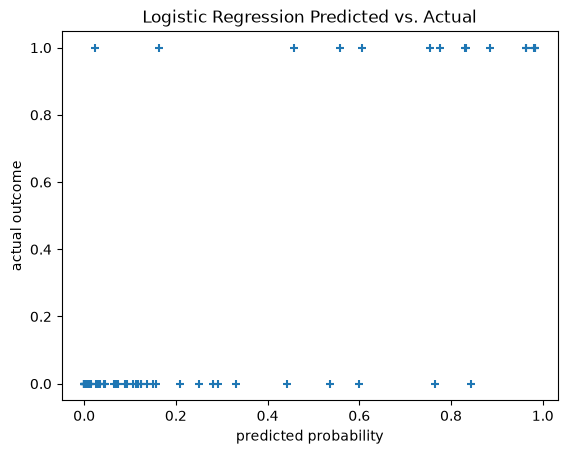

In [6]:
from matplotlib import pyplot as plt

predictions = [logistic(dot(beta, x_i)) for x_i in x_test]
plt.scatter(predictions, y_test, marker='+')
plt.xlabel("predicted probability")
plt.ylabel("actual outcome")
plt.title("Logistic Regression Predicted vs. Actual")
plt.show()
